In [40]:
pip install scipy

In [41]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from time import perf_counter


In [42]:
def fA(x):
 return (x - 3)**2 + 2
def fB(x):
 return x**4 - 3*x**2 + 2
xA_star = 3.0
xB_stars = np.array([-np.sqrt(3/2), np.sqrt(3/2)])
print("x*A =", xA_star)
print("x*B =", xB_stars)

x*A = 3.0
x*B = [-1.22474487  1.22474487]


In [43]:
def error_to_B_optimum(x_hat):
 return np.min(np.abs(x_hat - xB_stars))

# **TH1**

In [44]:
def grid_search_1d(f, a, b, step):
 xs = np.arange(a, b + step/2, step)
 values = np.array([f(x) for x in xs])
 idx = np.argmin(values)
 return xs[idx], values[idx], len(xs)
for step in [0.5, 0.1, 0.01]:
 x_hat, f_hat, n_eval = grid_search_1d(fA, -5, 8, step)
 err = abs(x_hat - xA_star)
 print(step, x_hat, f_hat, err, n_eval)


0.5 3.0 2.0 0.0 27
0.1 2.9999999999999716 2.0 2.842170943040401e-14 131
0.01 2.9999999999998295 2.0 1.7053025658242404e-13 1301


In [45]:
for step in [0.5, 0.1, 0.01]:
 x_hat, f_hat, n_eval = grid_search_1d(fB, -3, 3, step)
 err = error_to_B_optimum(x_hat)
 print(step, x_hat, f_hat, err, n_eval)

0.5 -1.0 0.0 0.22474487139158894 13
0.1 1.2000000000000037 -0.24640000000000128 0.02474487139158521 61
0.01 -1.220000000000038 -0.249865440000002 0.004744871391550998 601


# **TH2**

In [46]:
res_A = minimize_scalar(
 fA,
 bracket=(-5, 8),
 method="golden",
 options={"xtol": 1e-10, "maxiter": 1000}
)
print("x_hat =", res_A.x)
print("f_hat =", res_A.fun)
print("nfev =", res_A.nfev)
print("success =", res_A.success)
print("error =", abs(res_A.x - xA_star))


x_hat = 2.9999999853808497
f_hat = 2.0
nfev = 57
success = True
error = 1.4619150334738151e-08


In [47]:
res_B_left = minimize_scalar(
 fB, bracket=(-3, -1.2, 0), method="golden",
 options={"xtol": 1e-10}
)
res_B_right = minimize_scalar(
 fB, bracket=(0, 1.2, 3), method="golden",
 options={"xtol": 1e-10}
)
print("Left :", res_B_left.x, res_B_left.fun, res_B_left.nfev)
print("Right:", res_B_right.x, res_B_right.fun, res_B_right.nfev)

Left : -1.2247448774003344 -0.25000000000000044 54
Right: 1.2247448695341001 -0.25000000000000044 54


In [48]:
#bracket bao phủ cả hai cực tiểu
res_test = minimize_scalar(
    fB,
    bracket=(-3, 0, 3),
    method="golden",
    options={"xtol": 1e-10}
)

print("x =", res_test.x)
print("f(x) =", res_test.fun)
print("nfev =", res_test.nfev)
print("success =", res_test.success)

x = -1.2247448830813132
f(x) = -0.24999999999999956
nfev = 55
success = True


# **TH3**

In [49]:
def newton_1d(f1, f2, x0, tol=1e-8, max_iter=50, hess_eps=1e-12):
 x = float(x0)
 history = [x]
 status = "max_iter"
 for _ in range(max_iter):
  g = f1(x)
  h = f2(x)
  if abs(h) < hess_eps:
    status = "small_second_derivative"
    break
  x_new = x - g / h
  history.append(x_new)
  if abs(x_new - x) < tol:
    x = x_new
    status = "converged"
    break
  x = x_new
 return x, history, status

In [50]:
def fA1(x):
 return 2*(x - 3)
def fA2(x):
 return 2.0
def fB1(x):
 return 4*x**3 - 6*x
def fB2(x):
 return 12*x**2 - 6

In [51]:
x_hat, history, status = newton_1d(fA1, fA2, x0=0)
print("x_hat =", x_hat)
print("history =", history)
print("status =", status)

x_hat = 3.0
history = [0.0, 3.0, 3.0]
status = converged


In [52]:
for x0 in [-2, -1, 0.5, 2]:
    x_hat, history, status = newton_1d(fB1, fB2, x0)
    print("x0 =", x0)
    print("x_hat =", x_hat)
    print("history =", history)
    print("status =", status)

x0 = -2
x_hat = -1.224744871391589
history = [-2.0, -1.5238095238095237, -1.294653351902885, -1.2300277508417994, -1.2247787120083984, -1.2247448727940609, -1.224744871391589]
status = converged
x0 = -1
x_hat = -1.2247448713915892
history = [-1.0, -1.3333333333333333, -1.2367149758454108, -1.2249164451749897, -1.2247449074333125, -1.2247448713915905, -1.2247448713915892]
status = converged
x0 = 0.5
x_hat = 0.0
history = [0.5, -0.33333333333333337, 0.06349206349206349, -0.00034404301612836474, 5.4297155530416696e-11, 0.0]
status = converged
x0 = 2
x_hat = 1.224744871391589
history = [2.0, 1.5238095238095237, 1.294653351902885, 1.2300277508417994, 1.2247787120083984, 1.2247448727940609, 1.224744871391589]
status = converged


# **TH4**

In [53]:
for x0 in [-4, 0, 6]:
 x_hat, history, status = newton_1d(fA1, fA2, x0)
 print("x0=", x0,
 "x_hat=", x_hat,
 "iterations=", len(history)-1,
 "status=", status)


x0= -4 x_hat= 3.0 iterations= 2 status= converged
x0= 0 x_hat= 3.0 iterations= 2 status= converged
x0= 6 x_hat= 3.0 iterations= 2 status= converged


# **TH5**

In [54]:
starts = [-2, -0.5, 0.5, 2]
for x0 in starts:
 x_hat, history, status = newton_1d(fB1, fB2, x0)
 second = fB2(x_hat)
 if second > 0:
  kind = "local minimum"
 elif second < 0:
  kind = "local maximum"
 else:
  kind = "inconclusive"
 print(f"x0={x0:5.2f} -> x={x_hat: .9f}, "
 f"f={fB(x_hat): .6f}, {kind}, "
 f"iter={len(history)-1}, status={status}")


x0=-2.00 -> x=-1.224744871, f=-0.250000, local minimum, iter=6, status=converged
x0=-0.50 -> x= 0.000000000, f= 2.000000, local maximum, iter=5, status=converged
x0= 0.50 -> x= 0.000000000, f= 2.000000, local maximum, iter=5, status=converged
x0= 2.00 -> x= 1.224744871, f=-0.250000, local minimum, iter=6, status=converged


# **3.8**

In [55]:
test_starts = [0.7, 0.71, np.sqrt(0.5)]
for x0 in test_starts:
 x_hat, history, status = newton_1d(fB1, fB2, x0)
 print("x0 =", x0)
 print("status =", status)
 print("first iterates =", history[:6])
 print("final x =", x_hat)


x0 = 0.7
status = converged
first iterates = [0.7, -22.866666666666468, -15.259035656535877, -10.19458242916608, -6.829243455910126, -4.602167618808732]
final x = -1.224744871391589
x0 = 0.71
status = converged
first iterates = [0.71, 58.1969105691058, 38.80366890600145, 25.87770571048219, 17.26469453258673, 11.529136021080507]
final x = 1.224744871391589
x0 = 0.7071067811865476
status = small_second_derivative
first iterates = [0.7071067811865476]
final x = 0.7071067811865476


# **3.9**

In [56]:
def benchmark(callable_fn, repeat=200):
 t0 = perf_counter()
 result = None
 for _ in range(repeat):
  result = callable_fn()
  elapsed = perf_counter() - t0
 return result, elapsed / repeat
_, t_grid = benchmark(lambda: grid_search_1d(fA, -5, 8, 0.01))
_, t_gold = benchmark(lambda: minimize_scalar(
 fA, bracket=(-5, 8), method="golden",
 options={"xtol": 1e-10}
))
_, t_newton = benchmark(lambda: newton_1d(fA1, fA2, 0))
print("Grid average :", t_grid*1000, "ms")
print("Golden average:", t_gold*1000, "ms")
print("Newton average:", t_newton*1000, "ms")

Grid average : 0.6148352150012215 ms
Golden average: 0.36713632499868254 ms
Newton average: 0.0012851099995714321 ms


# **3.10**

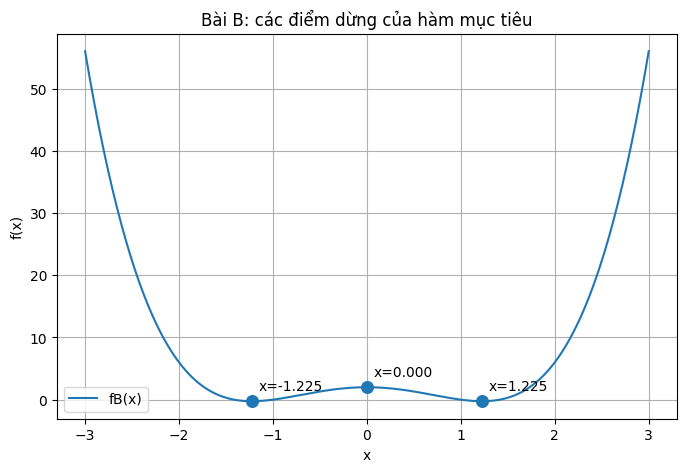

In [57]:
x = np.linspace(-3, 3, 500)
y = fB(x)
plt.figure(figsize=(8, 5))
plt.plot(x, y, label="fB(x)")
critical = np.array([-np.sqrt(3/2), 0, np.sqrt(3/2)])
plt.scatter(critical, fB(critical), s=70, zorder=3)
for xc in critical:
 plt.annotate(f"x={xc:.3f}", (xc, fB(xc)),
  textcoords="offset points", xytext=(5, 8))
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Bài B: các điểm dừng của hàm mục tiêu")
plt.grid(True)
plt.legend()
plt.show()

# Bài tập **1**

In [59]:
def benchmark(fn, repeat=200):
    t0 = perf_counter()
    for _ in range(repeat):
        result = fn()
    return result, (perf_counter() - t0) / repeat * 1000
# Grid Search
for step in [0.5, 0.1, 0.01]:
    (x, fx, n), t = benchmark(
        lambda: grid_search_1d(fA, -5, 8, step))
    print(f"Grid Search | step={step} | x={x:.6f} | "
          f"f={fx:.6f} | error={abs(x-3):.2e} | "
          f"n={n} | time={t:.4f} ms")
# Golden Section
res, t = benchmark(
    lambda: minimize_scalar(
        fA, bracket=(-5, 8), method="golden",
        options={"xtol": 1e-10}
    ))
print(f"Golden Section | x={res.x:.6f} | f={res.fun:.6f} | "
      f"error={abs(res.x-3):.2e} | n={res.nfev} | "
      f"time={t:.4f} ms")
# Newton
(res_x, history, status), t = benchmark(
    lambda: newton_1d(fA1, fA2, 0, tol=1e-8))
print(f"Newton | x={res_x:.6f} | f={fA(res_x):.6f} | "
      f"error={abs(res_x-3):.2e} | iter={len(history)-1} | "
      f"time={t:.4f} ms")

Grid Search | step=0.5 | x=3.000000 | f=2.000000 | error=0.00e+00 | n=27 | time=0.0375 ms
Grid Search | step=0.1 | x=3.000000 | f=2.000000 | error=2.84e-14 | n=131 | time=0.2803 ms
Grid Search | step=0.01 | x=3.000000 | f=2.000000 | error=1.71e-13 | n=1301 | time=1.6404 ms
Golden Section | x=3.000000 | f=2.000000 | error=1.46e-08 | n=57 | time=0.7730 ms
Newton | x=3.000000 | f=2.000000 | error=0.00e+00 | iter=2 | time=0.0027 ms


# Bài tập **2**

In [60]:
for step in [0.5, 0.2, 0.1, 0.05, 0.01]:
    x, fx, n = grid_search_1d(fB, -3, 3, step)
    error = min(abs(x + np.sqrt(3/2)), abs(x - np.sqrt(3/2)))

    print(f"step={step} | x={x:.6f} | "
          f"f={fx:.6f} | error={error:.6f} | n={n}")

step=0.5 | x=-1.000000 | f=0.000000 | error=0.224745 | n=13
step=0.2 | x=1.200000 | f=-0.246400 | error=0.024745 | n=31
step=0.1 | x=1.200000 | f=-0.246400 | error=0.024745 | n=61
step=0.05 | x=-1.200000 | f=-0.246400 | error=0.024745 | n=121
step=0.01 | x=-1.220000 | f=-0.249865 | error=0.004745 | n=601


# Bài tập **3**

In [61]:
x0_list = [-2.5, -2, -0.7, -0.5, 0, 0.5, 0.7, 2, 2.5]

for x0 in x0_list:
    x, history, status = newton_1d(fB1, fB2, x0, tol=1e-8)

    if fB2(x) > 0:
        kind = "Local minimum"
    elif fB2(x) < 0:
        kind = "Local maximum"
    else:
        kind = "Không xác định"

    print(f"x0={x0:5.2f} | xhat={x:.6f} | "
          f"f={fB(x):.6f} | iter={len(history)-1} | "
          f"type={kind} | status={status}")

x0=-2.50 | xhat=-1.224745 | f=-0.250000 | iter=7 | type=Local minimum | status=converged
x0=-2.00 | xhat=-1.224745 | f=-0.250000 | iter=6 | type=Local minimum | status=converged
x0=-0.70 | xhat=1.224745 | f=-0.250000 | iter=14 | type=Local minimum | status=converged
x0=-0.50 | xhat=0.000000 | f=2.000000 | iter=5 | type=Local maximum | status=converged
x0= 0.00 | xhat=0.000000 | f=2.000000 | iter=1 | type=Local maximum | status=converged
x0= 0.50 | xhat=0.000000 | f=2.000000 | iter=5 | type=Local maximum | status=converged
x0= 0.70 | xhat=-1.224745 | f=-0.250000 | iter=14 | type=Local minimum | status=converged
x0= 2.00 | xhat=1.224745 | f=-0.250000 | iter=6 | type=Local minimum | status=converged
x0= 2.50 | xhat=1.224745 | f=-0.250000 | iter=7 | type=Local minimum | status=converged


# Bài tập **4**

In [62]:
# Golden Section trên toàn đoạn [-3, 3]
res = minimize_scalar(
    fB,
    bracket=(-3, 0, 3),
    method="golden",
    options={"xtol": 1e-8})
print("Golden toàn đoạn:")
print(f"x = {res.x:.6f} | f(x) = {res.fun:.6f} | nfev = {res.nfev}")
# Golden Section chia thành 2 đoạn
res_left = minimize_scalar(
    fB,
    bracket=(-3, -1.2, 0),
    method="golden",
    options={"xtol": 1e-8})
res_right = minimize_scalar(
    fB,
    bracket=(0, 1.2, 3),
    method="golden",
    options={"xtol": 1e-8})
print("\nGolden chia đoạn:")
print(f"[-3,0] | x = {res_left.x:.6f} | f(x) = {res_left.fun:.6f} | nfev = {res_left.nfev}")
print(f"[0,3]  | x = {res_right.x:.6f} | f(x) = {res_right.fun:.6f} | nfev = {res_right.nfev}")

Golden toàn đoạn:
x = -1.224745 | f(x) = -0.250000 | nfev = 45

Golden chia đoạn:
[-3,0] | x = -1.224745 | f(x) = -0.250000 | nfev = 44
[0,3]  | x = 1.224745 | f(x) = -0.250000 | nfev = 44


# Bài tập **5**

In [63]:
fC = lambda x: (x - 3.073)**2 + 2
for step in [0.5, 0.1, 0.01, 0.001]:
    x, fx, n = grid_search_1d(fC, -5, 8, step)
    error = abs(x - 3.073)
    print(f"step={step} | x={x:.6f} | "
          f"f={fx:.6f} | error={error:.6f} | n={n}")

step=0.5 | x=3.000000 | f=2.005329 | error=0.073000 | n=27
step=0.1 | x=3.100000 | f=2.000729 | error=0.027000 | n=131
step=0.01 | x=3.070000 | f=2.000009 | error=0.003000 | n=1301
step=0.001 | x=3.073000 | f=2.000000 | error=0.000000 | n=13001
